<a href="https://colab.research.google.com/github/OJB-Quantum/MuMax3-How-To/blob/main/MuMax%20Notebooks/Heisenberg_Exchange_Spiral_AFM_MuMaxPlus.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
! echo "This machine runs" $(uname) "with" $(python --version) "and provides the following GPU/CUDA specs:"
! nvidia-smi

In [ ]:
!uv pip install mumaxplus matplotlib numpy

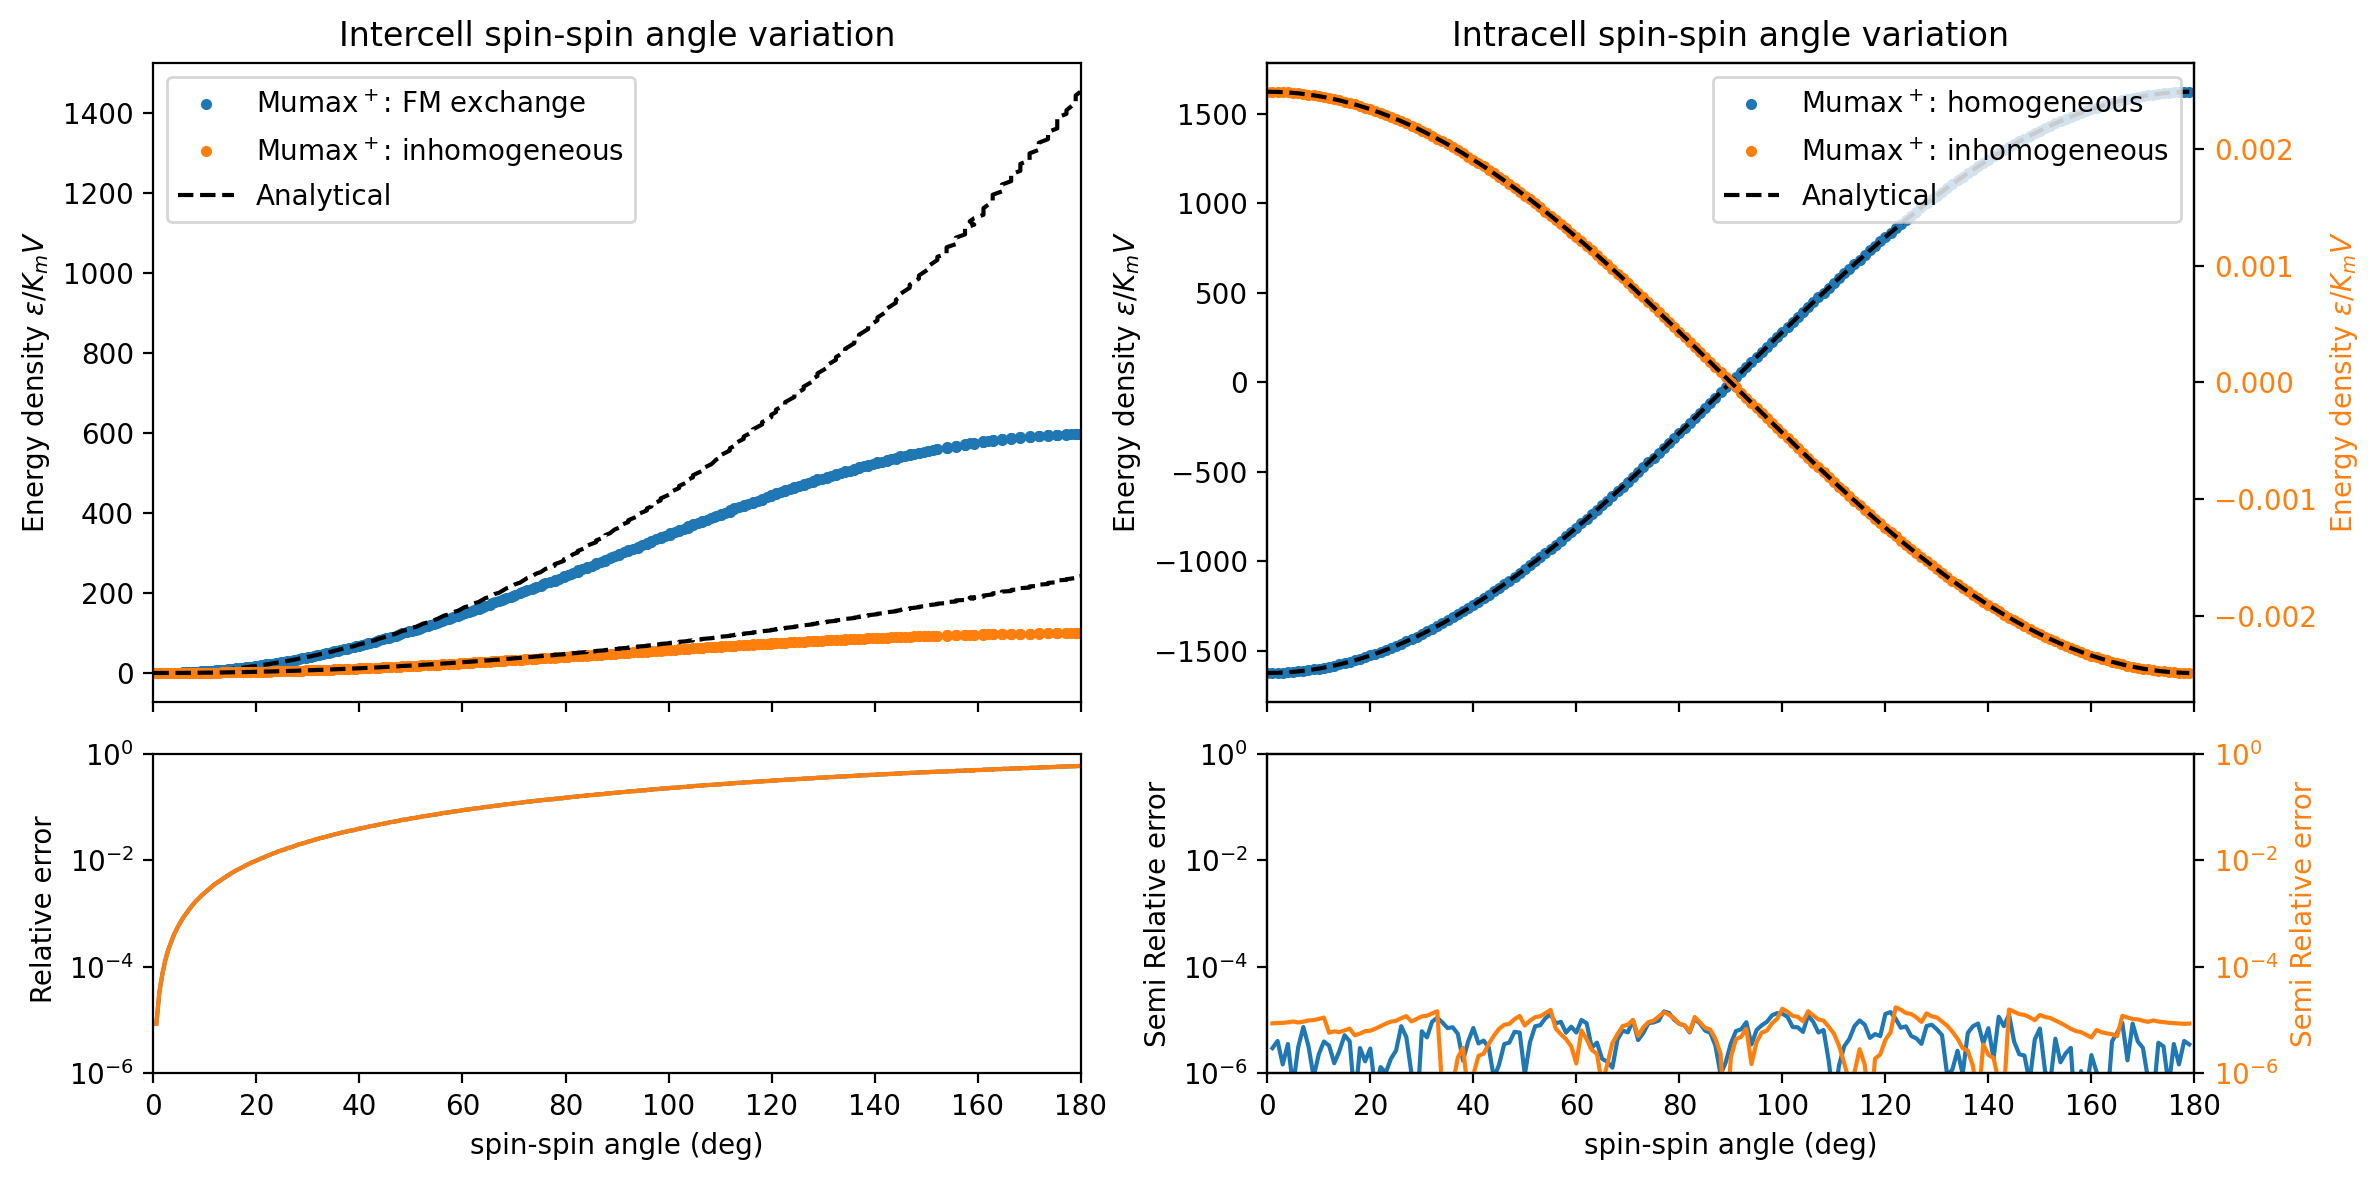

In [ ]:
"""This script compares numerical and analytical exchange energy contributions
for spiral magnetizations as a function of the angle between neighboring spins
and the angle between spins in the same simulation cell.
This is inspired by figure 5 of the paper "The design and verification of MuMax3".
https://doi.org/10.1063/1.4899186
"""

import matplotlib.pyplot as plt
import numpy as np

from mumaxplus import Antiferromagnet, Grid, World
from mumaxplus.util import *

plt.rcParams['figure.dpi'] = 200


def sub1helical():
    """Assumes X to be array from meshgrid, then returns three helical
    magnetization arrays for fast magnetization setting."""
    kx = k
    mx = np.cos(kx*X)
    my = np.sin(kx*X)
    mz = np.zeros_like(X)
    return mx, my, mz

def sub2helical():
    kx = k
    mx = -np.cos(kx*X + phi)
    my = -np.sin(kx*X + phi)
    mz = np.zeros_like(X)
    return mx, my, mz

def fm_ex(A, k):
    # Analytical FM (intrasublattice) exchange
    return A * k * k

def homo_ex(A0, a):
    # Analytical homogeneous AFM exchange
    return 4 * A0 * np.cos(phi) / (a * a) / 2

def inhomo_ex(A12, k):
    # Analytical inhomogeneous AFM exchange
    return A12 * (-k * k) * np.cos(phi) / 2

global k
global phi
k = 0
phi = 0

############ PARAMETER AND SIMULATION SET-UP ############

Ms = 400e3
A = 15e-12
A0 = -10e-12
A12 = -5e-12

length, width, thickness = 100e-6, 1e-9, 1e-9
V = length * width * thickness
Nx = int(length * 1e9)
nx, ny, nz = Nx, 1, 1
world = World(cellsize=(length / nx, width / ny, thickness / nz))

magnet = Antiferromagnet(world, Grid((nx, ny, nz)))
magnet.msat = Ms
magnet.aex = A
magnet.afmex_cell = A0
magnet.afmex_nn = A12

X, Y, Z = magnet.sub1.magnetization.meshgrid  # for fast magnetization setting

magnet.sub1.magnetization = sub1helical()
magnet.sub2.magnetization = sub2helical()

phases, angles = [], []
homogeneous, inhomogeneous, inhomogeneous_analytical, homogeneous_analytical = [], [], [], []
sub1_energies = np.zeros((2, 0))
analytical = np.zeros((2, 0))

fac = Km(Ms) * V
latcon = magnet.latcon.eval()[0,0,0,0]  # 0.35 nm is default

######### CALCULATE ENERGIES ##########

# ----- PHASE VARIATION -----

# Set k to arbitrary value for phase variation
k = 1e7
# Vary phase and calculate energies
for i in range(180):
      phi = i * np.pi/180
      magnet.sub1.magnetization = sub1helical()
      magnet.sub2.magnetization = sub2helical()
      phases.append(i)
      inhomogeneous.append(magnet.sub1.inhomogeneous_exchange_energy() / fac)
      homogeneous.append(magnet.sub1.homogeneous_exchange_energy() / fac)
      inhomogeneous_analytical.append(inhomo_ex(A12, k) / fac * V)
      homogeneous_analytical.append(homo_ex(A0, latcon) / fac * V)

# Reset phase
phi = 0
kk = 0

# ----- INTERCELL ANGLE VARIATION -----

while magnet.sub1.max_angle.eval() < np.pi-.01:

    k = kk * 1e7

    magnet.sub1.magnetization = sub1helical()
    magnet.sub2.magnetization = sub2helical()

    # Evaluate energies only for sublattice 1 (equal to sublattice 2 due to symmetry)
    sub1_energies = np.hstack((sub1_energies,
        np.array([ magnet.sub1.exchange_energy() / fac,
                   magnet.sub1.inhomogeneous_exchange_energy() / fac,
        ]).reshape(2, 1)))

    angles.append(magnet.sub1.max_angle() * 180 / np.pi)

    # Calculate analytical energies
    analytical = np.hstack((analytical,
        np.array([ fm_ex(A, k) / fac * V,
                   inhomo_ex(A12, k) / fac * V,
        ]).reshape(2, 1)))

    kk += 1

############ PLOTTER STUFF ############


def plotEnergyAndError(ax1, ax2, angle, E, theory, Elabel, Tlabel= "", c=None, err=""):
    # Plot energy and relative error
    ax1.plot(angle, E, '.', label=Elabel, color=c)
    ax1.plot(angle, theory, 'k--', label=Tlabel)
    # Plot semi-relative error if data goes through zero
    error = [np.abs((a - e) / a) if not err else np.abs((a - e)) / np.max(np.abs(theory)) for (e, a) in zip(E[1:], theory[1:])]

    ax2.plot(angle[1:], error, color=c)
    # Axes settings
    ax1.set_xlim(0, 180)
    ax1.set_ylabel(r"Energy density $\varepsilon / K_m V$")
    ax2.set_ylim(1e-6, 1)
    ax2.set_xlabel("spin-spin angle (deg)")
    ax2.set_ylabel(err + " " + "Relative error")
    ax2.set_yscale("log")

# Create figure and axes
fig, axs= plt.subplots(nrows=2, ncols=2, sharex=True, figsize=(12, 6), gridspec_kw={'height_ratios': [2, 1]})
fig.subplots_adjust(hspace=0)

# Plot Intercell FM exchange
plotEnergyAndError(axs[0, 0], axs[1, 0], angles, sub1_energies[0], analytical[0], r"Mumax$^+$: FM exchange")
plotEnergyAndError(axs[0, 0], axs[1, 0], angles, sub1_energies[1], analytical[1], r"Mumax$^+$: inhomogeneous", "Analytical")
axs[0, 0].legend()

# Plot Homogeneous AFM exchange
plotEnergyAndError(axs[0, 1], axs[1, 1], phases, homogeneous, homogeneous_analytical, r"Mumax$^+$: homogeneous", err="Semi")

# Plot inhomogeneous AFM exchange
#     Create secondary y-axis
ax2, ax3 = axs[0, 1].twinx(), axs[1, 1].twinx()
#     Set the color of the inhomogeneous plot
color = 'tab:orange'
ax2.set_ylabel('Energy density (inhomogeneous)', color=color)
ax2.yaxis.label.set_color(color)
ax3.yaxis.label.set_color(color)
ax2.tick_params(axis='y', labelcolor=color)
ax3.tick_params(axis='y', labelcolor=color)
#     Actual plot
plotEnergyAndError(ax2, ax3, phases, inhomogeneous, inhomogeneous_analytical, r"Mumax$^+$: inhomogeneous", "Analytical", c=color, err="Semi")
#     Create unified legend for both y axes
lines_1, labels_1 = axs[0, 1].get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()
ax2.legend(lines_1 + lines_2, labels_1 + labels_2, loc='upper right')

# Global titles
axs[0, 0].set_title("Intercell spin-spin angle variation")
axs[0, 1].set_title("Intracell spin-spin angle variation")

fig.tight_layout()
plt.show()